# MDPToolbox vs Marmote vs MDPSolver

Les 51 modèles du catalogue, avec leurs paramètres par défaut, et les 17 solveurs
de ces trois bibliothèques sont ajoutés explicitement, un par un.

Utiliser un noyau Python 3.11+ avec les dépendances installées depuis la racine :
```sh
python -m pip install -e ".[notebooks,mdptoolbox,marmote,mdpsolver,maze]"
```

Le benchmark vérifie la précision absolue par le résidu complet de Bellman.
Le timeout s'applique à chaque essai de solveur ; les modèles réutilisent leur
cache lorsqu'il existe. Utiliser MDPSolver 0.10.2 ou plus récent pour le correctif
VI/SOR ; les exports historiques en 0.10.1 peuvent contenir les anciennes erreurs.

In [1]:
import random

import numpy as np

from mdpforge import Benchmark

DISCOUNT = 0.9
SIZE = "small"
PRECISION = 1e-3
REPEATS = 3
SEED = 0
TIMEOUT = 10  # Secondes par essai ; None désactive l'isolation en processus.

np.random.seed(SEED)
random.seed(SEED)

Loading/building model 'access_control'...
Added MDP '500_2_access_control' (500 states, 2 actions) in 0.002 s
Loading/building model 'admission'...
Added MDP '108_2_admission_control' (108 states, 2 actions) in 0.001 s
Loading/building model 'ambulance'...
Added MDP '500_10_ambulance' (500 states, 10 actions) in 0.535 s
Loading/building model 'ambulance_relocation'...
Added MDP '1000_10_ambulance_relocation' (1000 states, 10 actions) in 0.035 s
Loading/building model 'elevator'...
Added MDP '5000_5_elevator' (5000 states, 5 actions) in 0.005 s
Loading/building model 'impatience'...
Added MDP '100_10_queue_impatience' (100 states, 10 actions) in 0.002 s
Loading/building model 'queue_network'...
Added MDP '125_3_queue_network_4' (125 states, 3 actions) in 0.001 s
Loading/building model 'tandem'...
Added MDP '4900_9_tandem' (4900 states, 9 actions) in 0.008 s
Loading/building model 'tandem_choice'...
Added MDP '1024_256_tandem_choice' (1024 states, 256 actions) in 12.207 s
Loading/buildi

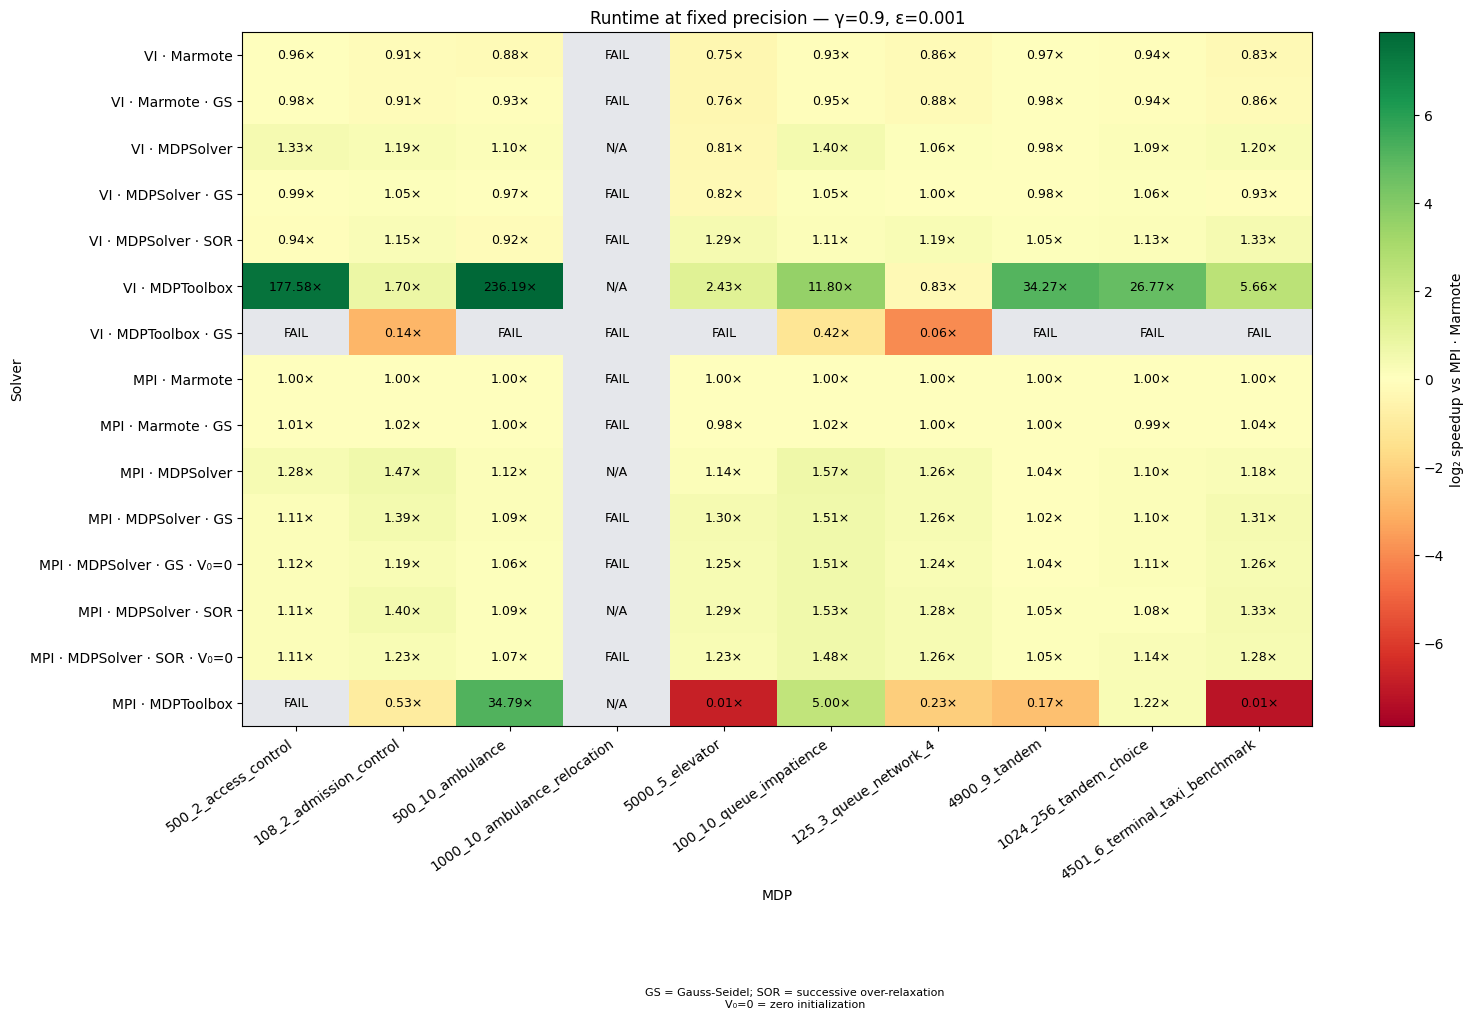

(<Figure size 1600x1025 with 2 Axes>,
 <Axes: title={'center': 'Runtime at fixed precision — γ=0.9, ε=0.001'}, xlabel='MDP', ylabel='Solver'>)

In [2]:
bench = Benchmark(default_solvers=False)

bench.reset()
bench.add_solver(family=["vi", "mpi"], backend=["mdpsolver", "marmote", "mdptoolbox"])
bench.add_mdp(category="service_operations", size=SIZE, verbose=True)
results = bench.run(
    discount=DISCOUNT,
    precision=PRECISION,
    repeats=REPEATS,
    seed=SEED,
    timeout=TIMEOUT,
    verbose=True,
)
results.plot_heat()

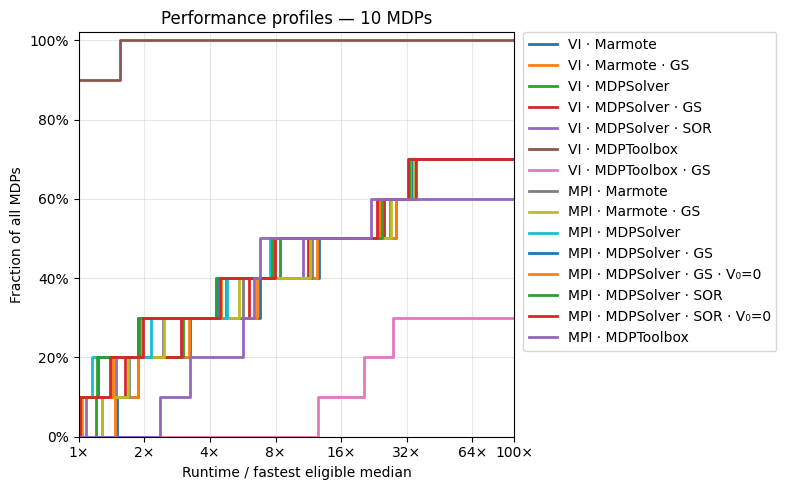

(<Figure size 800x500 with 1 Axes>,
 <Axes: title={'center': 'Performance profiles — 10 MDPs'}, xlabel='Runtime / fastest eligible median', ylabel='Fraction of all MDPs'>)

In [4]:
results.plot_performance_profile()